# Logistics Analysis: Food Delivery Times

## dataset: Food_Delivery_Times.csv (1,000 orders, 9 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Food_Delivery_Times.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Number of rows, column: ", df.shape[0],',' , df.shape[1])

Number of rows, column:  1000 , 9


In [4]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [6]:
df.isnull().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

Order_ID                    int64
Distance_km               float64
Weather                    object
Traffic_Level              object
Time_of_Day                object
Vehicle_Type               object
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

In [9]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


## Fill missing Values

In [10]:
# Fill missing categorical values with the mode

for col in ['Weather', 'Traffic_Level','Time_of_Day']:
    df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing courier experience with the median
df['Courier_Experience_yrs'] = df['Courier_Experience_yrs'].fillna(
    df['Courier_Experience_yrs'].median()
)

print("Missing values handled successfully!")

Missing values handled successfully!


In [11]:
df.isnull().sum()

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

## Check for Invalid Values

In [12]:
print("Distance <= 0:", (df['Distance_km'] <=0).sum())

print("Delivery time <= 0:", (df['Delivery_Time_min'] <=0).sum())
print("Preparation time <= 0:", (df['Preparation_Time_min'] <=0).sum())
print("Negative courier experience:", (df['Courier_Experience_yrs'] < 0).sum())



Distance <= 0: 0
Delivery time <= 0: 0
Preparation time <= 0: 0
Negative courier experience: 0


## Check Categorical Values

In [13]:
print("Weather categories:")
print(df['Weather'].unique())

print("\nTraffic levels:")
print(df['Traffic_Level'].unique())

print("\nTimes of day:")
print(df['Time_of_Day'].unique())

print("\nVehicle types:")
print(df['Vehicle_Type'].unique())

Weather categories:
['Windy' 'Clear' 'Foggy' 'Rainy' 'Snowy']

Traffic levels:
['Low' 'Medium' 'High']

Times of day:
['Afternoon' 'Evening' 'Night' 'Morning']

Vehicle types:
['Scooter' 'Bike' 'Car']


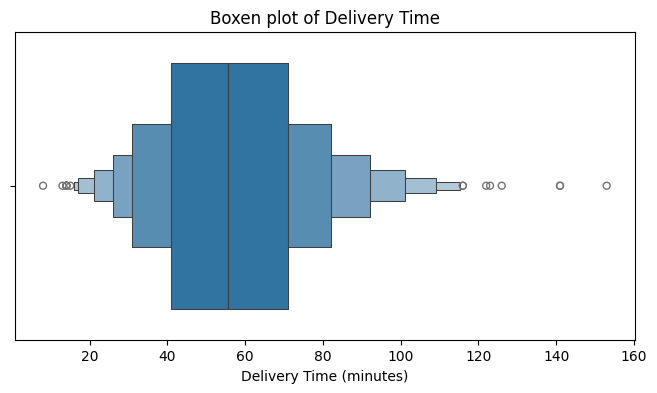

In [14]:
plt.figure(figsize=(8, 4))
sns.boxenplot(x=df['Delivery_Time_min'])
plt.title('Boxen plot of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.show()

In [15]:
Q1 = df['Delivery_Time_min'].quantile(0.25)
Q3 = df['Delivery_Time_min'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Delivery_Time_min'] < lower_bound) |
    (df['Delivery_Time_min'] > upper_bound) 
    
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Number of potential outliers:", len(outliers))

Q1: 41.0
Q3: 71.0
IQR: 30.0
Lower boundary: -4.0
Upper boundary: 116.0
Number of potential outliers: 6


In [16]:
# Inspect the outlier orders before deciding what to do
print(outliers[['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level',
                'Preparation_Time_min', 'Delivery_Time_min']])

     Order_ID  Distance_km Weather Traffic_Level  Preparation_Time_min  \
29        948        18.05   Clear        Medium                    10   
127       446        18.97   Clear           Low                    25   
379       814        18.46   Clear        Medium                    29   
452       394        15.64   Rainy           Low                    20   
784       385        14.83   Rainy           Low                    19   
924       428        17.81   Windy          High                    21   

     Delivery_Time_min  
29                 123  
127                141  
379                153  
452                141  
784                126  
924                122  


**Outlier decision:** 6 orders (0.6% of the data) exceed the upper IQR bound
of 116 minutes. All six are long-distance deliveries (14.8 to 19 km), a range
where delivery times are naturally higher (orders over 14.8 km average about
79 minutes). No impossible or invalid values were found, so these orders were
kept as genuine slow deliveries. When the predictive model is built, its
errors on these cases will be checked.

# Calculating basic KPIs

In [17]:
# Total number of orders
total_orders = df['Order_ID'].nunique()

# Average delivery time
avg_delivery_time = df['Delivery_Time_min'].mean()

# Average Delivery distance
avg_distance = df['Distance_km'].mean()

# Average preparation time
avg_preparation_time = df['Preparation_Time_min'].mean()

# Average courier experience
avg_courier_experience = df['Courier_Experience_yrs'].mean()

# Display KPIs
print("Total orders:", round(total_orders, 2))
print("Average Delivery Time:", round(avg_delivery_time, 2), "minutes")
print("Average Delivery Distance:", round(avg_distance, 2), "km")
print("Average Preparation Time:", round(avg_preparation_time, 2), "minutes")
print("Average Courier Experience:", round(avg_courier_experience, 2), "years")

Total orders: 1000
Average Delivery Time: 56.73 minutes
Average Delivery Distance: 10.06 km
Average Preparation Time: 16.98 minutes
Average Courier Experience: 4.59 years


## Performance KPIs
These KPIs measure delivery performance against an assumed on-time target
of 60 minutes.

In [18]:
ON_TIME_TARGET = 60  # minutes (assumed service-level target)

# KPI 1: On-time delivery rate (% of orders within the target)
on_time_rate = (df['Delivery_Time_min'] <= ON_TIME_TARGET).mean() * 100

# KPI 2: Delivery minutes per km (total minutes / total km)
min_per_km = df['Delivery_Time_min'].sum() / df['Distance_km'].sum()

# KPI 3: Extra delay in high traffic compared with low traffic
traffic_means = df.groupby('Traffic_Level')['Delivery_Time_min'].mean()
traffic_delay = traffic_means['High'] - traffic_means['Low']

kpi_table = pd.DataFrame({
    "KPI": [
        "Average delivery time (min)",
        f"On-time delivery rate (<= {ON_TIME_TARGET} min, %)",
        "Delivery minutes per km",
        "High-traffic delay vs low traffic (min)"
    ],
    "Value": [
        round(avg_delivery_time, 2),
        round(on_time_rate, 1),
        round(min_per_km, 2),
        round(traffic_delay, 2)
    ]
})

kpi_table

,KPI,Value
0,Average delivery time (min),56.73
1,"On-time delivery rate (<= 60 min, %)",58.50
2,Delivery minutes per km,5.64
3,High-traffic delay vs low traffic (min),11.92


In [19]:
df['On_Time'] = df['Delivery_Time_min'] <= ON_TIME_TARGET

print("On-time rate by traffic level (%):")
print((df.groupby('Traffic_Level')['On_Time'].mean() * 100).round(1))

print("\nOn-time rate by weather (%):")
print((df.groupby('Weather')['On_Time'].mean() * 100).round(1))

On-time rate by traffic level (%):
Traffic_Level
High      45.7
Low       63.7
Medium    59.8
Name: On_Time, dtype: float64

On-time rate by weather (%):
Weather
Clear    64.4
Foggy    52.4
Rainy    56.9
Snowy    40.2
Windy    56.2
Name: On_Time, dtype: float64


**KPI interpretation:** Only 58.5% of orders are delivered within the 60-minute
target, so about 4 in 10 orders are late. Performance drops sharply in snowy
weather (40.2% on time) and in high traffic (45.7% on time). High traffic adds
about 12 minutes to the average delivery. These conditions are the main
targets for improvement.

## Analyse Delivery Time by Wheather

Average Delivery Time by Weather Condition:
Weather
Snowy    67.11
Rainy    59.79
Foggy    59.47
Windy    55.46
Clear    53.15
Name: Delivery_Time_min, dtype: float64


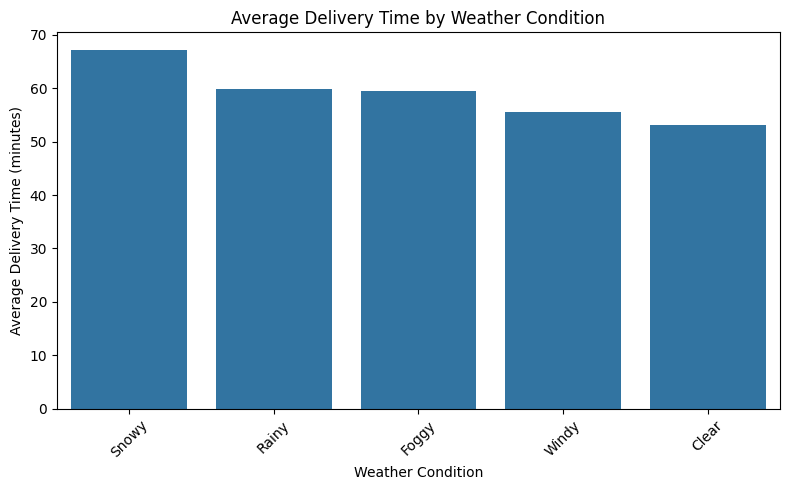

In [20]:
weather_analysis = (
    df.groupby('Weather')['Delivery_Time_min']
    .mean()
    .sort_values(ascending=False)
)

print("Average Delivery Time by Weather Condition:")
print(weather_analysis.round(2))

plt.figure(figsize=(8,5))

sns.barplot(
    x=weather_analysis.index,
    y=weather_analysis.values
)

plt.title('Average Delivery Time by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Delivery Time (minutes)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Analyse Delivery Time by Traffic Level

In [21]:
# Average time delivery time
traffic_analysis = df.groupby('Traffic_Level')['Delivery_Time_min'].mean()

traffic_analysis = traffic_analysis.sort_values(ascending=False)

print("Average Delivery Time by Traffic Level:")
print(traffic_analysis.round(2))

Average Delivery Time by Traffic Level:
Traffic_Level
High      64.81
Medium    56.45
Low       52.89
Name: Delivery_Time_min, dtype: float64


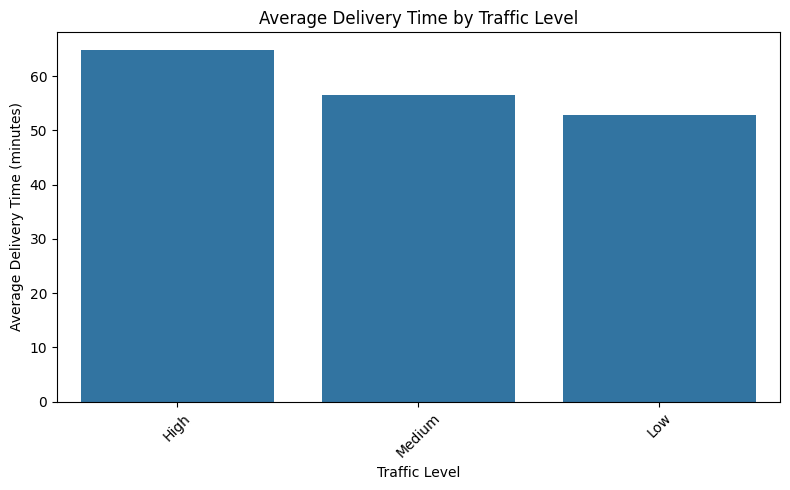

In [22]:
# Visualising the result
plt.figure(figsize=(8,5))

sns.barplot(
    x=traffic_analysis.index,
    y=traffic_analysis.values
)

plt.title('Average Delivery Time by Traffic Level')
plt.xlabel("Traffic Level")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Analyse Delivery Time by Distance

In [23]:
correlation = df['Distance_km'].corr(df['Delivery_Time_min'])

print("Correlation between Distance and Delivery Time:", round(correlation, 3))

Correlation between Distance and Delivery Time: 0.781


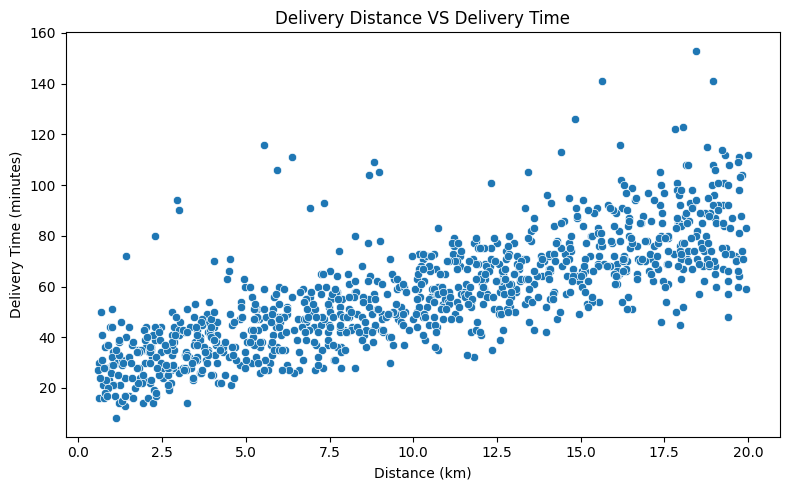

In [24]:
# Visualisation
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Distance_km',
    y='Delivery_Time_min'
)

plt.title("Delivery Distance VS Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()

## Preparation Time vs. Delivery Time

In [25]:
# Correlation calculation
correlation = df['Preparation_Time_min'].corr(
    df['Delivery_Time_min']
)

print("Correlation between Preparation Time and Delivery Time:", round(correlation, 3))

Correlation between Preparation Time and Delivery Time: 0.307


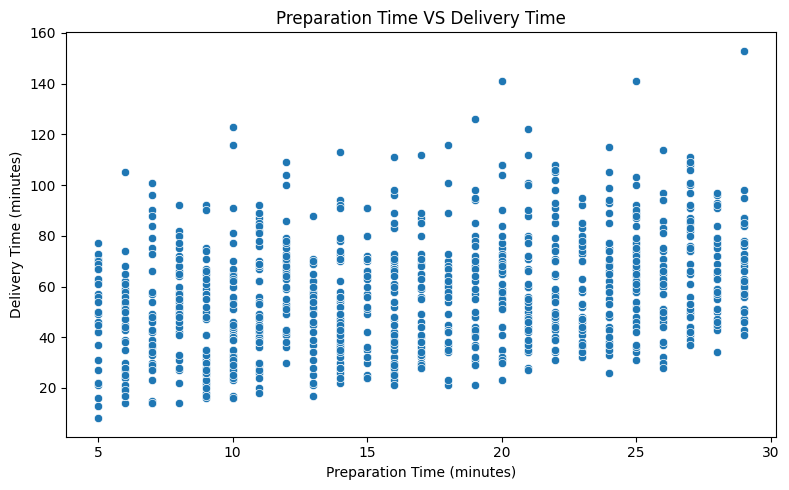

In [26]:
# Visualisation

plt.figure(figsize=(8,5))

sns.scatterplot(
    data = df,
    x = 'Preparation_Time_min',
    y = 'Delivery_Time_min'
)

plt.title('Preparation Time VS Delivery Time')
plt.xlabel('Preparation Time (minutes)')
plt.ylabel('Delivery Time (minutes)')

plt.tight_layout()
plt.show()

## Analyse Delivery Time by Vehicle Type

In [27]:
# Average delivery Time
vehicle_analysis = (
    df.groupby('Vehicle_Type')['Delivery_Time_min']
    .mean()
    .sort_values(ascending=False)
)

print("Average Delivery Time by Vehicle Type:")
print(vehicle_analysis.round(2))

Average Delivery Time by Vehicle Type:
Vehicle_Type
Car        58.20
Bike       56.57
Scooter    56.05
Name: Delivery_Time_min, dtype: float64


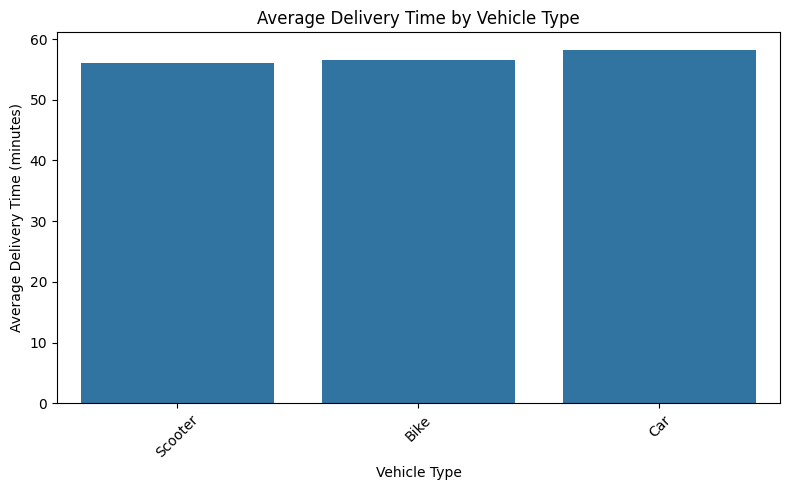

In [28]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='Vehicle_Type',
    y='Delivery_Time_min',
    errorbar=None
)

plt.title("Average Delivery Time by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Analyse Delivery Time by Courier Experience

In [29]:
# Correlation calculation

correlation = df['Courier_Experience_yrs'].corr(
    df['Delivery_Time_min']
)

print(
    "Correlation between Courier Experience and Delivery Time:",
    round(correlation, 3)
)

Correlation between Courier Experience and Delivery Time: -0.089


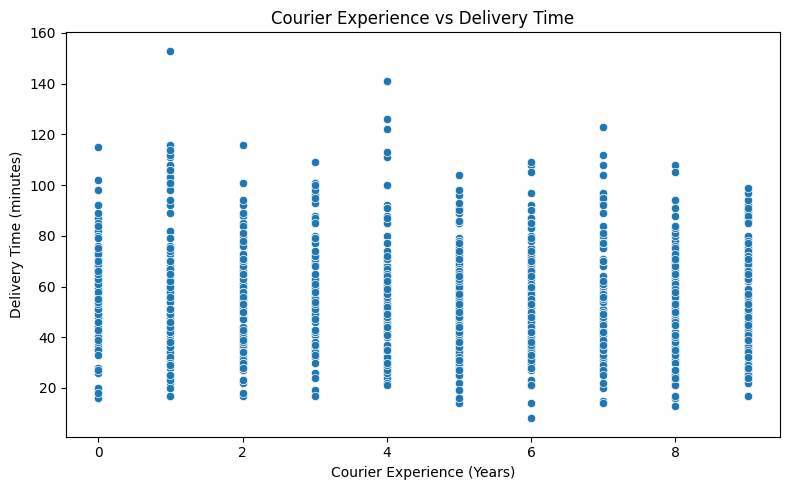

In [30]:
# Scatter plot
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Courier_Experience_yrs',
    y='Delivery_Time_min'
)

plt.title('Courier Experience vs Delivery Time')
plt.xlabel('Courier Experience (Years)')
plt.ylabel('Delivery Time (minutes)')

plt.tight_layout()
plt.show()

### Analyse Delivery Time by Time of Day

In [31]:
print(df['Time_of_Day'].unique())

['Afternoon' 'Evening' 'Night' 'Morning']


In [32]:
# Average delivery time 
time_analysis = (
    df.groupby('Time_of_Day')['Delivery_Time_min']
    .mean()
    .sort_values(ascending=False)
)

print("Average Delivery Time by Time of Day:")
print(time_analysis.round(2))

Average Delivery Time by Time of Day:
Time_of_Day
Evening      57.48
Morning      57.01
Afternoon    56.08
Night        55.21
Name: Delivery_Time_min, dtype: float64


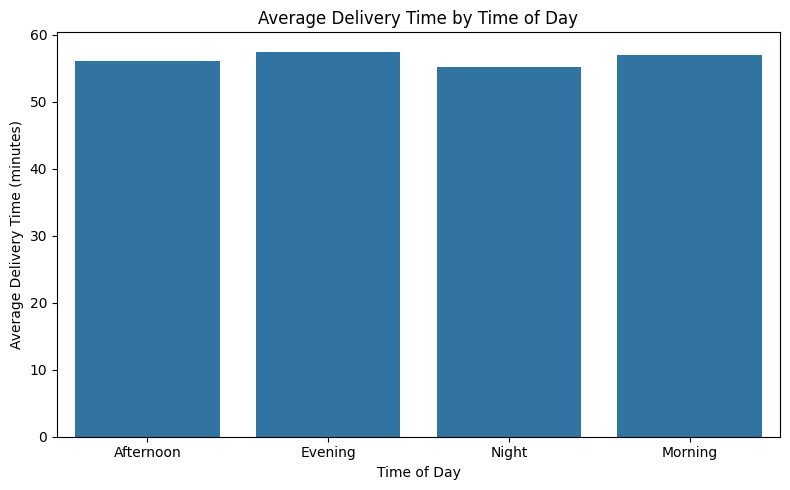

In [33]:
# Visualisation
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='Time_of_Day',
    y='Delivery_Time_min',
    errorbar=None
)

plt.title("Average Delivery Time by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Average Delivery Time (minutes)")

plt.tight_layout()
plt.show()

### Create a Correlation Heatmap

In [34]:
# Select the numerical columns relevant to our analysis
numeric_columns = [
    'Distance_km',
    'Preparation_Time_min',
    'Courier_Experience_yrs',
    'Delivery_Time_min'
]

# Correlation matrix
correlation_matrix = df[numeric_columns].corr()

# Display the results

print("Correlation Matrix: ", round(correlation_matrix, 2))

Correlation Matrix:                          Distance_km  Preparation_Time_min  \
Distance_km                    1.00                 -0.01   
Preparation_Time_min          -0.01                  1.00   
Courier_Experience_yrs        -0.01                 -0.03   
Delivery_Time_min              0.78                  0.31   

                        Courier_Experience_yrs  Delivery_Time_min  
Distance_km                              -0.01               0.78  
Preparation_Time_min                     -0.03               0.31  
Courier_Experience_yrs                    1.00              -0.09  
Delivery_Time_min                        -0.09               1.00  


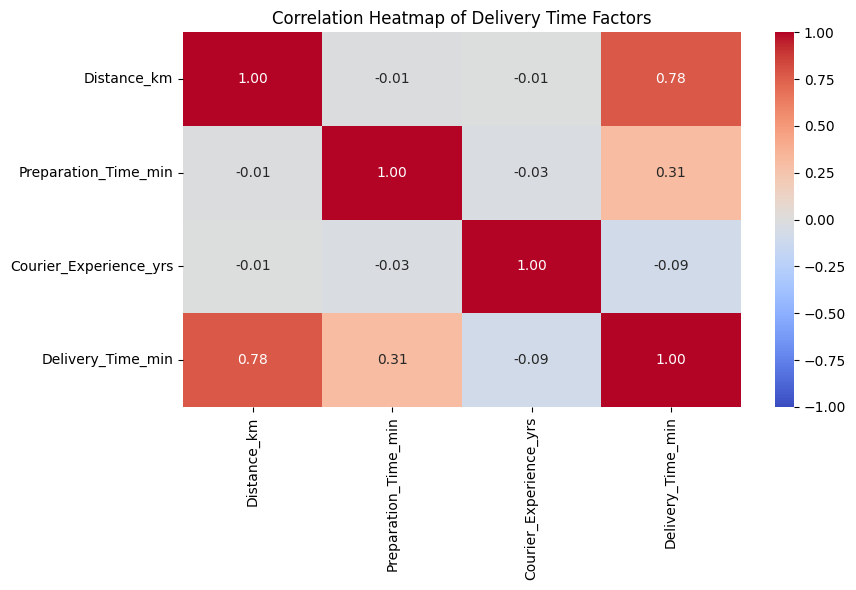

In [35]:
# Visualise the matrix with heatmap

plt.figure(figsize=(9,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Delivery Time Factors')
plt.tight_layout()
plt.show()

### Business Insights & Recommendations

In [36]:
traffic_means = df.groupby('Traffic_Level')['Delivery_Time_min'].mean()

high_traffic_time = traffic_means['High']
low_traffic_time = traffic_means['Low']

traffic_difference = high_traffic_time - low_traffic_time

print("Average delivery time in high traffic: ", round(high_traffic_time, 2), "minutes")
print("Average delivery time in low traffic: ", round(low_traffic_time, 2), "minutes")
print("Difference: ", round(traffic_difference, 2), "minutes")

Average delivery time in high traffic:  64.81 minutes
Average delivery time in low traffic:  52.89 minutes
Difference:  11.92 minutes


#### Creating a Business Insights table

In [37]:
# Calculate every value from the data
corr_dist = df['Distance_km'].corr(df['Delivery_Time_min'])
corr_prep = df['Preparation_Time_min'].corr(df['Delivery_Time_min'])
corr_exp = df['Courier_Experience_yrs'].corr(df['Delivery_Time_min'])

weather_means = df.groupby('Weather')['Delivery_Time_min'].mean()
tod_means = df.groupby('Time_of_Day')['Delivery_Time_min'].mean()

business_insight = pd.DataFrame({
    "Factor": [
        "Delivery Distance",
        "Traffic Level",
        "Weather",
        "Preparation Time",
        "Courier Experience",
        "Time of Day"
    ],
    "Finding": [
        f"Strong positive correlation with delivery time ({corr_dist:.3f})",
        f"High traffic averages {traffic_means['High']:.2f} min; low traffic averages {traffic_means['Low']:.2f} min",
        f"Snowy weather averages {weather_means['Snowy']:.2f} min; clear weather averages {weather_means['Clear']:.2f} min",
        f"Positive correlation with delivery time ({corr_prep:.3f})",
        f"Very weak negative correlation with delivery time ({corr_exp:.3f})",
        f"Evening averages {tod_means['Evening']:.2f} min; night averages {tod_means['Night']:.2f} min"
    ],
    "Business Recommendation": [
        "Use distance when estimating delivery times and assigning orders",
        "Plan routes and delivery schedules around traffic conditions",
        "Add extra time buffers and adjust courier supply during bad weather",
        "Monitor preparation delays and coordinate restaurants with couriers",
        "Experience alone is not a strong driver; investigate other factors",
        "Monitor demand and performance across different times of day"
    ]
})

business_insight

,Factor,Finding,Business Recommendation
0,Delivery Distance,Strong positive correlation with delivery time...,Use distance when estimating delivery times an...
1,Traffic Level,High traffic averages 64.81 min; low traffic a...,Plan routes and delivery schedules around traf...
2,Weather,Snowy weather averages 67.11 min; clear weathe...,Add extra time buffers and adjust courier supp...
3,Preparation Time,Positive correlation with delivery time (0.307),Monitor preparation delays and coordinate rest...
4,Courier Experience,Very weak negative correlation with delivery t...,Experience alone is not a strong driver; inves...
5,Time of Day,Evening averages 57.48 min; night averages 55....,Monitor demand and performance across differen...


## Predictive Modelling: Delivery Time

### Prepare the data

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Target
y = df['Delivery_Time_min']

# Features: remove the ID, the target, and the On_Time column
features = df.drop(columns =['Order_ID', 'Delivery_Time_min', 'On_Time'])

# Convert text columns to 0/1 columns
X = pd.get_dummies(features, drop_first=True)

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows: ", X_train.shape[0])
print("Test rows: ", X_test.shape[0])
print("Number of features: ", X.shape[1])

Training rows:  800
Test rows:  200
Number of features:  14


### Train and compare the two models

In [39]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE (min)": round(mean_absolute_error(y_test, pred), 2),
        "RMSE (min)": round(np.sqrt(mean_squared_error(y_test, pred)), 2),
        "R2": round(r2_score(y_test, pred), 3)
    })

result_table = pd.DataFrame(results)
result_table

,Model,MAE (min),RMSE (min),R2
0,Linear Regression,5.90,8.83,0.826
1,Random Forest,7.02,10.22,0.767


### Show which factors matter most

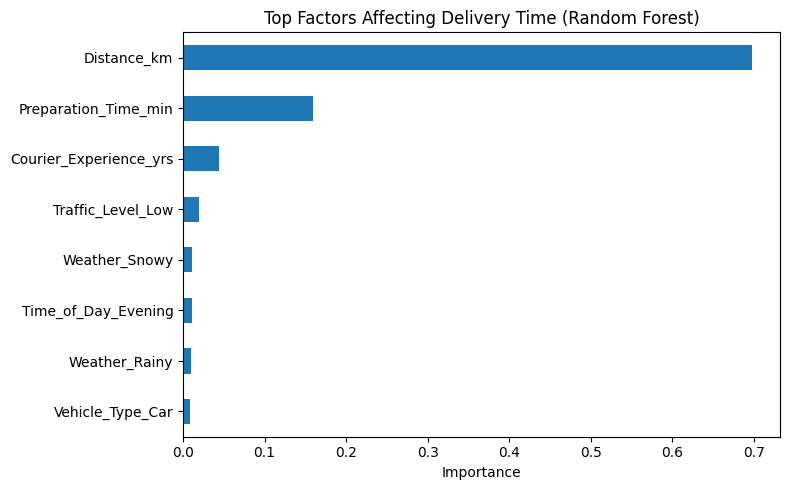

In [40]:
rf_model = models["Random Forest"]

importance = pd.Series(rf_model.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=True).tail(8)

plt.figure(figsize=(8, 5))
importance.plot(kind='barh')
plt.title('Top Factors Affecting Delivery Time (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

### Check the long-distance orders

In [41]:
pred_lr = pd.Series(predictions["Linear Regression"], index=X_test.index)

long_trips = X_test['Distance_km'] >= 14.8

mae_long = mean_absolute_error(y_test[long_trips], pred_lr[long_trips])
mae_short = mean_absolute_error(y_test[~long_trips], pred_lr[~long_trips])

print("Test orders of 14.8 km or more: ", long_trips.sum())
print("MAE for long-distance orders: ", round(mae_long, 2), "minutes")
print("MAE for short-distance orders: ", round(mae_short, 2), "minutes")

Test orders of 14.8 km or more:  55
MAE for long-distance orders:  8.94 minutes
MAE for short-distance orders:  4.75 minutes


**Model interpretation:** Linear Regression performed better than Random Forest
(MAE 5.90 vs 7.02 minutes, R² 0.826 vs 0.767), which suggests that delivery
time is mostly a linear function of distance and the other factors. On average,
predictions are off by about 6 minutes. Distance is by far the most important
factor, followed by preparation time. Errors are larger for long-distance
orders (about 8.9 minutes) than for shorter ones (about 4.8 minutes), so
long deliveries are the hardest to predict.